In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,RocCurveDisplay)

In [4]:

df = pd.read_csv("loan_data.csv")


In [5]:
print(df.head())
print(df.shape)

   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0           561  

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

MISSING VALUE CHECK

In [ ]:
missing_values = df.isnull().sum()
print(missing_values)
if missing_values.sum() == 0:
    print("\nResult: No missing values found.")
else:
    print("\nResult: Missing values found.")

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Result: No missing values found.


DUPLICATE CHECK

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("Result: No duplicate rows found.")

Number of duplicate rows: 0
Result: No duplicate rows found.


TARGET VARIABLE ANALYSIS

In [ ]:
TARGET = "loan_status"
print("Target variable:", TARGET)
print("\nTarget values:")
print(df[TARGET].value_counts())
print("\nTarget percentage:")
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

Target variable: loan_status

Target values:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Target percentage:
loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64


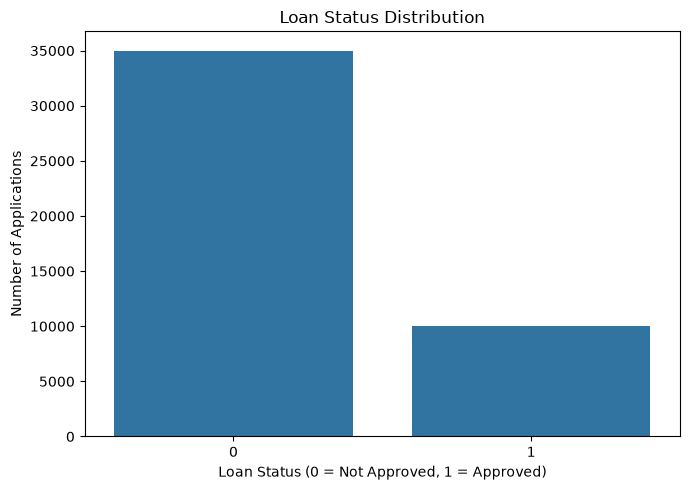

In [10]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x=TARGET
)
plt.title("Loan Status Distribution")
plt.xlabel("Loan Status (0 = Not Approved, 1 = Approved)")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

In [11]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

FEATURE TYPES

In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("\nNumerical features:")
for feature in numerical_features:
    print("-", feature)
print("\nCategorical features:")
for feature in categorical_features:
    print("-", feature)



Numerical features:
- person_age
- person_income
- person_emp_exp
- loan_amnt
- loan_int_rate
- loan_percent_income
- cb_person_cred_hist_length
- credit_score

Categorical features:
- person_gender
- person_education
- person_home_ownership
- loan_intent
- previous_loan_defaults_on_file


C:\Users\Mansoorvali\AppData\Local\Temp\ipykernel_12400\1653703785.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [13]:
for column in numerical_features:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ).sum()
    percentage = (outliers / len(X)) * 100
    print(
        f"{column:<35} "
        f"{outliers:>6} outliers "
        f"({percentage:.2f}%)"
    )


person_age                            2188 outliers (4.86%)
person_income                         2218 outliers (4.93%)
person_emp_exp                        1724 outliers (3.83%)
loan_amnt                             2348 outliers (5.22%)
loan_int_rate                          124 outliers (0.28%)
loan_percent_income                    744 outliers (1.65%)
cb_person_cred_hist_length            1366 outliers (3.04%)
credit_score                           467 outliers (1.04%)


In [14]:
X["age_group"] = pd.cut(
    X["person_age"],
    bins=[0, 25, 35, 50, 100, np.inf],
    labels=[
        "Young",
        "Adult",
        "Middle_Age",
        "Senior",
        "Very_Senior"
    ]
)
print(
    "Created feature: age_group"
)
print("\nAge group distribution:")
print(X["age_group"].value_counts())


Created feature: age_group

Age group distribution:
age_group
Young          20441
Adult          20073
Middle_Age      4158
Senior           321
Very_Senior        7
Name: count, dtype: int64


TRAIN-TEST SPLIT

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])



Training samples: 36000
Testing samples : 9000


In [ ]:
numeric_pipeline = Pipeline( steps=[("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])
categorical_pipeline = Pipeline(steps=[( "imputer", SimpleImputer(strategy="most_frequent")),( "encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=False ) )])
preprocessor = ColumnTransformer(transformers=[("numeric",numeric_pipeline,  numerical_features), ( "categorical", categorical_pipeline, categorical_features + ["age_group"] ) ])


In [17]:
models = {"Logistic Regression":LogisticRegression(max_iter=2000,random_state=42),
    "Decision Tree":DecisionTreeClassifier(random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1),
    "KNN":KNeighborsClassifier(n_neighbors=5),
    "SVM":SVC(probability=True,random_state=42)}


MODEL TRAINING AND EVALUATION

In [ ]:
results = {}
trained_models = {}
for name, model in models.items():
    print("\nTraining:", name)
    pipeline = Pipeline(
        steps=[("preprocessor",preprocessor),
            ("model",model)])
    pipeline.fit(X_train,y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test,predictions,zero_division=0)
    recall = recall_score(y_test,predictions,zero_division=0)
    f1 = f1_score(y_test,predictions,zero_division=0)
    roc_auc = roc_auc_score(y_test,probabilities
    )
    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }
    trained_models[name] = pipeline
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC-AUC  : {roc_auc:.4f}")


Training: Logistic Regression
Accuracy : 0.8996
Precision: 0.7884
Recall   : 0.7490
F1 Score : 0.7682
ROC-AUC  : 0.9562

Training: Decision Tree
Accuracy : 0.8989
Precision: 0.7717
Recall   : 0.7740
F1 Score : 0.7728
ROC-AUC  : 0.8543

Training: Random Forest
Accuracy : 0.9274
Precision: 0.8946
Recall   : 0.7635
F1 Score : 0.8238
ROC-AUC  : 0.9749

Training: KNN
Accuracy : 0.8941
Precision: 0.7907
Recall   : 0.7120
F1 Score : 0.7493
ROC-AUC  : 0.9242

Training: SVM


c:\Users\Mansoorvali\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy : 0.9170
Precision: 0.8554
Recall   : 0.7540
F1 Score : 0.8015
ROC-AUC  : 0.9640


MODEL COMPARISON

In [19]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)
print(
    results_df.round(4)
)


                     Accuracy  Precision  Recall  F1 Score  ROC-AUC
Random Forest          0.9274     0.8946  0.7635    0.8238   0.9749
SVM                    0.9170     0.8554  0.7540    0.8015   0.9640
Decision Tree          0.8989     0.7717  0.7740    0.7728   0.8543
Logistic Regression    0.8996     0.7884  0.7490    0.7682   0.9562
KNN                    0.8941     0.7907  0.7120    0.7493   0.9242


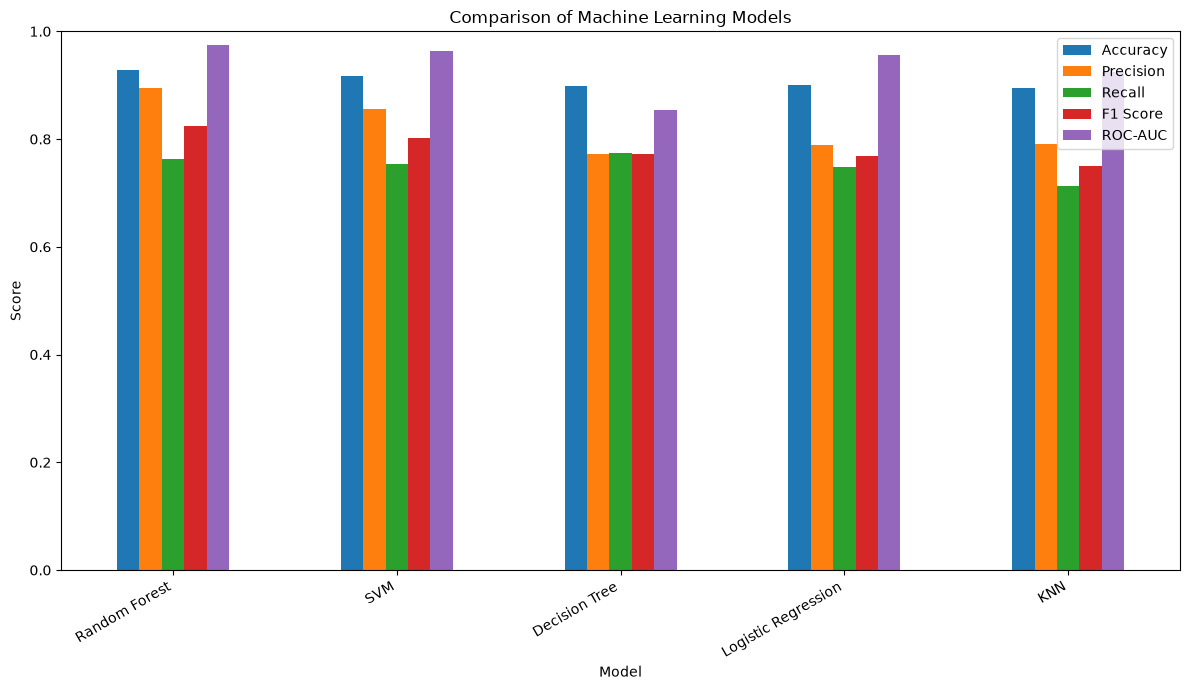

In [20]:
results_df.plot(
    kind="bar",
    figsize=(12, 7)
)
plt.title("Comparison of Machine Learning Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=30,ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()



 BEST MODEL

In [21]:
best_model_name = results_df.index[0]
print("Best model based on F1 Score:",best_model_name)

Best model based on F1 Score: Random Forest


HYPERPARAMETER TUNING

In [22]:
if best_model_name == "Logistic Regression":
    model = LogisticRegression(max_iter=2000, random_state=42)
    parameter_grid = { "model__C": [0.01, 0.1, 1, 10]}
elif best_model_name == "Decision Tree":
    model = DecisionTreeClassifier(random_state=42)
    parameter_grid = {
        "model__max_depth": [5, 10, 15, None],
        "model__min_samples_split": [2, 5, 10]
    }
elif best_model_name == "Random Forest":
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    parameter_grid = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5]
    }
elif best_model_name == "KNN":
    model = KNeighborsClassifier()
    parameter_grid = {
        "model__n_neighbors": [3, 5, 7, 9],
        "model__weights": ["uniform", "distance"]
    }
else:
    model = SVC(
        probability=True,
        random_state=42
    )
    parameter_grid = {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
final_model = grid_search.best_estimator_
print("\nBest parameters:")
print(grid_search.best_params_)
print("\nBest cross-validation F1 Score:",round(grid_search.best_score_, 4))


Best parameters:
{'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best cross-validation F1 Score: 0.8236


In [ ]:
final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]


In [28]:

final_accuracy = accuracy_score(y_test,final_predictions)
final_precision = precision_score(y_test,final_predictions,zero_division=0)
final_recall = recall_score(y_test,final_predictions,zero_division=0)
final_f1 = f1_score(y_test,final_predictions,zero_division=0)
final_roc_auc = roc_auc_score(y_test,final_probabilities)


print("\nModel:",best_model_name)
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1 Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_roc_auc:.4f}")



Model: Random Forest
Accuracy : 0.9277
Precision: 0.8951
Recall   : 0.7640
F1 Score : 0.8244
ROC-AUC  : 0.9740


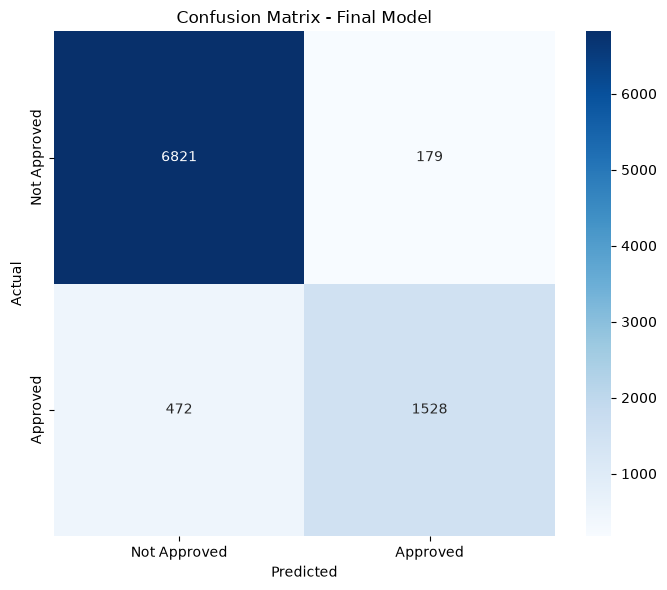

In [ ]:
cm = confusion_matrix(y_test,final_predictions)
plt.figure(figsize=(7, 6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Not Approved","Approved"],
    yticklabels=[Not Approved","Approved"])
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


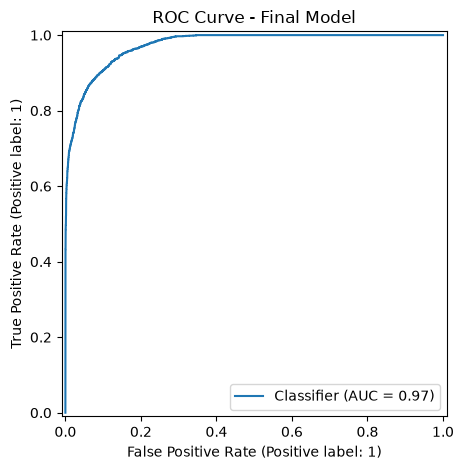

In [ ]:
RocCurveDisplay.from_predictions(y_test,final_probabilities)
plt.title("ROC Curve - Final Model")
plt.tight_layout()
plt.show()

In [ ]:
sample = pd.DataFrame({
    "person_age": [28],"person_gender": ["male"],"person_education": ["Bachelor"],
    "person_income": [60000],"person_emp_exp": [5],"person_home_ownership": ["RENT"],
    "loan_amnt": [10000],"loan_intent": ["EDUCATION"],"loan_int_rate": [10.5],
    "loan_percent_income": [0.17],"cb_person_cred_hist_length": [5],"credit_score": [700],"previous_loan_defaults_on_file": ["No"]})

sample["age_group"] = pd.cut(
    sample["person_age"],
    bins=[0,25,35,50,100,np.inf],
    labels=["Young","Adult","Middle_Age","Senior","Very_Senior"])


sample_prediction = final_model.predict(sample)[0]
sample_probability = final_model.predict_proba(sample)[0][1]
if sample_prediction == 1:
    status = "APPROVED"
else:
    status = "NOT APPROVED"
print("\nSample applicant:")
print(sample.to_string(index=False))
print("\nPredicted Loan Status:",status)
print(f"Approval Probability: "f"{sample_probability * 100:.2f}%")



Sample applicant:
 person_age person_gender person_education  person_income  person_emp_exp person_home_ownership  loan_amnt loan_intent  loan_int_rate  loan_percent_income  cb_person_cred_hist_length  credit_score previous_loan_defaults_on_file age_group
         28          male         Bachelor          60000               5                  RENT      10000   EDUCATION           10.5                 0.17                           5           700                             No     Adult

Predicted Loan Status: NOT APPROVED
Approval Probability: 13.91%
